# 02 · Encoding: one-hot + padding
Step 2 of the thesis workflow (after `01_jets_meta`).

**Input:** `data/raw/journal_entries_4203.csv` (never modified), `data/derived/meta.parquet` (notebook 01)
**Output:** `data/derived/X_onehot.npz` (sparse, rows in `meta.parquet` order) + `data/derived/onehot_features.json` (column names, feature groups, fitted parameters)

Decisions used here (details and rationale: Decisions sheet of `Thesis_Execution_Plan.xlsx`, review of 25 Nov 2026):

| ID | What | Setting |
|---|---|---|
| D9 | line order inside the padding | debit first, then account number, then amount (largest first) |
| D10 | scalers | fitted per fiscal year, on the same entries as the detector (follows D6) |
| D4 | time features | `lag_days` (continuous) + `weekend` + `nwh`; `promptly` built but **off** (binning of `lag_days`) |
| D13 | entry-level fields | `user` once per entry; `tax_rate` and `n_lines` built but **off** (determined by the account pattern; section 6.1) |
| D11 | extra time features | `nwh_dist`, hour sin/cos, weekday sin/cos checked and **dropped**; built only to reproduce the data checks |

All candidate features are stored once. A model run selects columns by group with `select_columns()`, so no rebuild is needed to switch a group on or off.

Main setting = 131 columns (encoding version v3; n_lines dropped after the redundancy check of 26 Nov).

In [1]:
# cell_02_01
import sys
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)

RAW_REL = Path("data/raw/journal_entries_4203.csv")


def find_project_root(marker: Path = RAW_REL) -> Path:
    # walk up from the working directory until `marker` exists (same as notebook 01)
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found from {here} upwards")


ROOT = find_project_root()
sys.path.insert(0, str(ROOT))
from src.load import load_lines
from src import encode as fe

DATA = ROOT / RAW_REL
DERIVED = ROOT / "data" / "derived"
FY1 = 2023          # tuning year (D6); FY2 = 2024 is the reporting year (scalers are fitted per year, D10)
print("project root:", ROOT)

project root: C:\MyWorks\Thesis\Jet


## 1. Load raw lines and the meta table

In [2]:
# cell_02_02
lines = load_lines(DATA)                   # src/load.py (adds fy, line_no)
meta = pd.read_parquet(DERIVED / "meta.parquet")

print(lines.shape, meta.shape)
assert len(meta) == 102_429 and lines["posting_id"].nunique() == len(meta)
assert set(lines["posting_id"]) == set(meta["posting_id"])

(256232, 21) (102429, 11)


## 2. Which fields are per line and which are per entry?

If a field has one value inside every `posting_id`, it is encoded **once per entry**, not once per line slot. Repeating it in 4 slots would count it up to 4 times in every distance (LOF, kNN) without adding information.

In [3]:
# cell_02_03
g = lines.groupby("posting_id", sort=False)
check = {c: int((g[c].nunique() > 1).sum())
         for c in ["user", "tax_rate", "entered_date", "document_date", "promptly", "weekend", "nwh",
                   "gl_account", "cd_flag", "amount"]}
pd.Series(check, name="entries with >1 value")

user                  0
tax_rate              0
entered_date          0
document_date         0
promptly              0
weekend               0
nwh                   0
gl_account       102429
cd_flag          102429
amount            51373
Name: entries with >1 value, dtype: int64

In [4]:
# cell_02_04
# expected: 0 for all entry-level fields; > 0 for gl_account, cd_flag, amount (line level)
for c in fe.ENTRY_COLS:
    assert check[c] == 0, c

### Line patterns (debit/credit sequence as written in the CSV)

In [5]:
# cell_02_05
pattern = g["cd_flag"].agg("".join).rename("csv_pattern")
pat = (pd.DataFrame({"csv_pattern": pattern})
       .join(meta.set_index("posting_id")[["label"]])
       .groupby("csv_pattern")["label"].agg(entries="size", anomalies="sum"))
pat

,entries,anomalies
csv_pattern,,
CCD,60,0
DC,51056,542
DCC,18000,91
DDC,33312,217
DDDC,1,0


In [6]:
# cell_02_06
# the only 4-line entry: it alone fills slot 4, so the one-hot encoding will make it very isolated
four = meta.loc[meta["n_lines"] == 4, "posting_id"].tolist()
print(four)
lines[lines["posting_id"].isin(four)].drop(columns=["gl_account_name", "text"])

['p_2']


,posting_id,document_date,posting_date,entered_date,gl_account,amount,cd_flag,user,tax_rate,ref_id,promptly,weekend,nwh,label,marking,top_n,high_cash,fy,line_no
256224,p_2,2024-02-06,2024-02-06,2024-02-06 09:00:00,1700,1490.90,D,Alice,0.19,p_1,1,0,0,0,0,0,0,2024,0
256225,p_2,2024-02-06,2024-02-06,2024-02-06 09:00:00,2020,63.36,D,Alice,0.19,p_1,1,0,0,0,0,0,0,2024,1
256226,p_2,2024-02-06,2024-02-06,2024-02-06 09:00:00,1576,295.31,D,Alice,0.19,p_1,1,0,0,0,0,0,0,2024,2
256227,p_2,2024-02-06,2024-02-06,2024-02-06 09:00:00,1600,1849.57,C,Alice,0.19,p_1,1,0,0,0,0,0,0,2024,3


## 3. Build the encoding

In [7]:
# cell_02_07
X, feature_info, params, sorted_lines, ent = fe.build_onehot(lines, meta)   # scalers per fiscal year (D10)
print(X.shape, f"non-zeros: {X.nnz:,}")
pd.Series([f["group"] for f in feature_info]).value_counts().rename("columns per group")

(102429, 140) non-zeros: 1,935,190


lines             126
calendar_flags      4
tax_rate            2
hour_cyc            2
wday_cyc            2
n_lines             1
promptly            1
lag_days            1
nwh_dist            1
Name: columns per group, dtype: int64

## 4. D9 — does the line order matter in this dataset?

Count entries whose CSV line order differs from the D9 order, then check whether the CSV order is **consistent within each booking pattern**. Only an inconsistent order would give entries with the same content different vectors.

In [8]:
# cell_02_08
changed = fe.order_changes(sorted_lines)
print(f"entries with CSV order != D9 order: {changed.sum():,} of {len(changed):,} "
      f"({changed.mean():.1%})")
(pd.DataFrame({"changed": changed}).join(pattern)
   .groupby("csv_pattern")["changed"].agg(entries="size", changed="sum"))

entries with CSV order != D9 order: 51,253 of 102,429 (50.0%)


,entries,changed
csv_pattern,,
CCD,60,60
DC,51056,0
DCC,18000,18000
DDC,33312,33192
DDDC,1,1


In [9]:
# cell_02_08b
# is the CSV order consistent per booking pattern? (25 Nov: yes - each of the 29 patterns is stored in one order)
csv_order = lines.groupby("posting_id", sort=False).apply(lambda x: tuple(zip(x["cd_flag"], x["gl_account"])))
content = csv_order.apply(lambda t: tuple(sorted(t)))
orders_per_pattern = pd.DataFrame({"content": content, "csv": csv_order}).groupby("content")["csv"].nunique()
print(f"booking patterns: {len(orders_per_pattern)}, patterns stored in more than one order: {(orders_per_pattern > 1).sum()}")
# -> on this ledger the stored order is a generator property (expense, input tax, counterpart);
#    D9 sorts anyway so that the vector depends on the content only, not on how lines are stored.

booking patterns: 29, patterns stored in more than one order: 0


In [10]:
# cell_02_09
# example for the thesis: one entry before and after sorting
ex = changed[changed].index[0]
cols = ["posting_id", "csv_pos", "slot", "cd_flag", "gl_account", "gl_account_name", "amount"]
sorted_lines.loc[sorted_lines["posting_id"] == ex, cols].sort_values("csv_pos")

,posting_id,csv_pos,slot,cd_flag,gl_account,gl_account_name,amount
0,a_1,0,1,D,3400,"Cost of merchandise, 19% input tax",112.42
1,a_1,1,0,D,1576,"Deductible input tax, 19%",21.36
2,a_1,2,2,C,1600,Trade payables,133.78


In [11]:
# cell_02_10
# tie-break check: same side and same account twice inside one entry?
dup = sorted_lines.groupby(["posting_id", "cd_flag", "gl_account"]).size()
print("entries needing the amount tie-break:", int((dup > 1).sum()))

entries needing the amount tie-break: 0


## 5. Sanity checks

In [12]:
# cell_02_11
names = [f["name"] for f in feature_info]
col = {n: i for i, n in enumerate(names)}
is1 = (meta["fy"] == FY1).to_numpy()

def colv(name):
    return np.asarray(X[:, col[name]].todense()).ravel()

# (a) every slot has exactly one account category and one side category (PAD included)
for s in range(1, fe.MAX_LINES + 1):
    a = [i for i, f in enumerate(feature_info) if f["slot"] == s and f["name"].startswith(f"s{s}_acct_")]
    c = [i for i, f in enumerate(feature_info) if f["slot"] == s and f["name"].startswith(f"s{s}_cd_")]
    assert (np.asarray(X[:, a].sum(axis=1)).ravel() == 1).all()
    assert (np.asarray(X[:, c].sum(axis=1)).ravel() == 1).all()

# (b) slot use matches n_lines
for s in range(1, fe.MAX_LINES + 1):
    filled = colv(f"s{s}_acct_PAD") == 0
    assert (filled == (meta["n_lines"].to_numpy() >= s)).all()

# (c) scaled values: every fiscal year in [0, 1] (scalers fitted per year, D10)
for nm in ["s1_amount", "lag_days", "nwh_dist"]:
    v = colv(nm)
    print(f"{nm:10s} FY1 [{v[is1].min():.3f}, {v[is1].max():.3f}]   FY2 [{v[~is1].min():.3f}, {v[~is1].max():.3f}]")
    for m_ in (is1, ~is1):
        assert v[m_].min() >= -1e-9 and v[m_].max() <= 1 + 1e-9

# (d) nwh_dist = 0 exactly when nwh = 0
assert ((ent["nwh_dist_raw"].to_numpy() > 0) == (ent["nwh"].to_numpy() == 1)).all()

# (e) promptly bins agree with lag_days (1 = 0-9, 2 = 10-29, 3 = 30+ days)
bins = pd.cut(ent["lag_days_raw"], [-np.inf, 9, 29, np.inf], labels=[1, 2, 3]).astype(int)
print("promptly vs lag bins, mismatches:", int((bins.to_numpy() != ent["promptly"].to_numpy()).sum()))

# (f) weekend flag agrees with the weekday of entered_date (Sat = 5, Sun = 6)
wk = np.select([ent["wday"] == 5, ent["wday"] == 6], [1, 2], 0)
print("weekend vs weekday, mismatches:", int((wk != ent["weekend"].to_numpy()).sum()))

s1_amount  FY1 [0.016, 1.000]   FY2 [0.012, 1.000]
lag_days   FY1 [0.000, 1.000]   FY2 [0.000, 1.000]
nwh_dist   FY1 [0.000, 1.000]   FY2 [0.000, 1.000]
promptly vs lag bins, mismatches: 0
weekend vs weekday, mismatches: 0


## 6. Feature checks with figures (Ch. 3)

Each figure supports one decision of the Decisions sheet. Figures that use labels (anomaly rates) are drawn on **FY1 only**, so no label of the reporting year FY2 enters a feature decision (D6). The redundancy check and the duplicate check use no labels and run on the whole ledger. All figures are saved as PNG and PDF to `results/figures/`.

In [13]:
# cell_02_14
from src import figures as fg

FIG = ROOT / "results" / "figures"
df = fg.entry_frame(lines, meta, ent, sorted_lines)
df1 = df[df["fy"] == FY1]                       # labels: FY1 only (D6)
print(f"whole ledger {len(df):,} entries | FY1 {len(df1):,} entries, {int(df1['label'].sum())} anomalies, "
      f"base rate {df1['label'].mean():.2%}")

whole ledger 102,429 entries | FY1 51,064 entries, 423 anomalies, base rate 0.83%


### 6.1 Redundancy check of the entry-level fields (D4, D13; no labels)

Rule of the feature engineering: every fact is counted once. A field that is fully determined by another field (functional dependency) adds no information and only gives that fact more weight in the distances of LOF and the autoencoder. Numeric fields are cut into 10 quantile bins for Cramér's V.

functional dependencies (A determines B):
determines determined  values of A  values of B
   pattern    n_lines           29            3
   pattern   tax_rate           29            2
  lag_days   promptly          121            3


WindowsPath('C:/MyWorks/Thesis/Jet/results/figures/fe_association_heatmap.png')

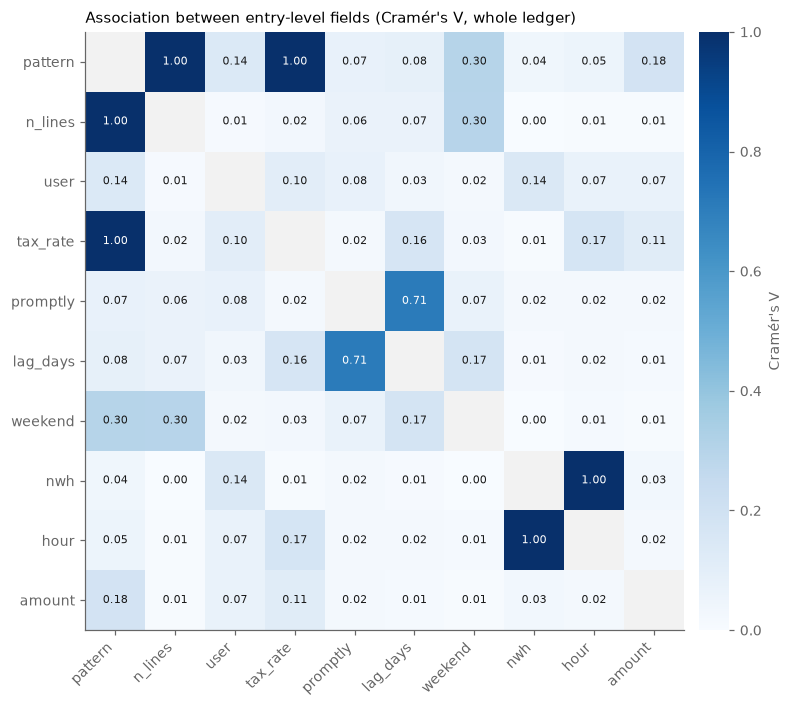

In [14]:
# cell_02_15
red_cols = ["pattern", "n_lines", "user", "tax_rate", "promptly", "lag_days", "weekend", "nwh", "hour", "amount"]
fd = fg.functional_dependencies(df, ["pattern", "n_lines", "user", "tax_rate", "promptly", "lag_days", "weekend", "nwh"])
print("functional dependencies (A determines B):")
print(fd.to_string(index=False))
assoc = fg.association_matrix(df, red_cols, numeric_bins={"lag_days": 10, "amount": 10})
fig = fg.fig_association_heatmap(assoc, "Association between entry-level fields (Cramér's V, whole ledger)")
fg.save(fig, "fe_association_heatmap", FIG)
# expected: pattern -> n_lines, pattern -> tax_rate, lag_days -> promptly; all three are not features (D4, D13)

### 6.2 D1 — the item text is a stand-in for the price (FY1)

,entries,anomalies,rate,median_amount
text,,,,
Gardening Gloves,5143,31,0.0060,7.32
Watering Can,5091,15,0.0029,58.91
Rake,4995,17,0.0034,94.61
Shovel,5213,19,0.0036,99.53
Garden Shears,4992,24,0.0048,106.39
Garden Hose,4941,17,0.0034,117.81
Hedge Trimmer,5119,42,0.0082,362.36
Leaf Blower,5178,39,0.0075,386.16
Wheelbarrow,4950,61,0.0123,472.99


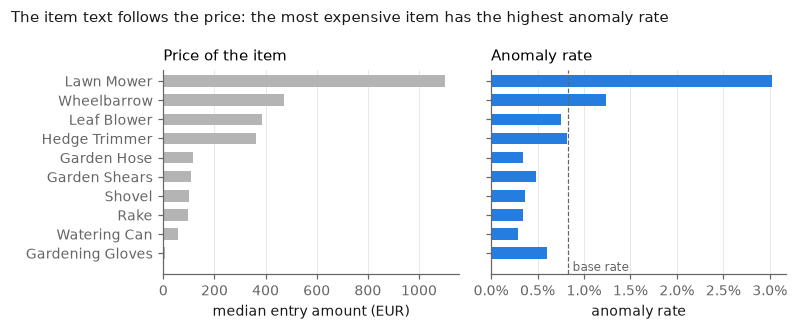

In [15]:
# cell_02_16
items = df["text"].value_counts().loc[lambda s: s > 1000].index.tolist()   # the 10 garden item names
fig, t_text = fg.fig_text_vs_price(df1, items)
fg.save(fig, "fe_d1_text_vs_price", FIG)
t_text.round(4)

### 6.3 D4 — anomaly rate by delay (FY1)

,entries,anomalies,rate
lag_bin,,,
0–4,18852,131,0.0069
5–9,28010,135,0.0048
10–14,3510,88,0.0251
15–19,82,4,0.0488
20–29,162,3,0.0185
30–44,196,36,0.1837
45–59,164,16,0.0976
60–89,32,3,0.0938
90+,56,7,0.1250


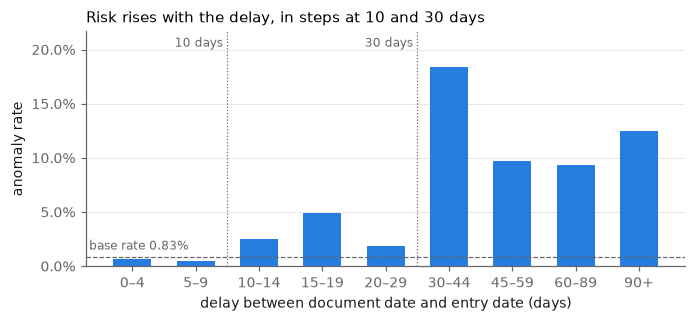

In [16]:
# cell_02_17
fig, t_lag = fg.fig_rate_by_lag(df1)
fg.save(fig, "fe_d4_rate_by_lag", FIG)
t_lag.round(4)

### 6.4 D11 — time of day and weekday (FY1)

entries  anomalies    rate
                                  dist                             
by distance outside working hours 0–0.5       84         14  0.1667
                                  0.5–1       46          4  0.0870
                                  1–2        128         12  0.0938
                                  2–3        125         16  0.1280
                                  3–4         34          4  0.1176
                                  4–6         54          4  0.0741

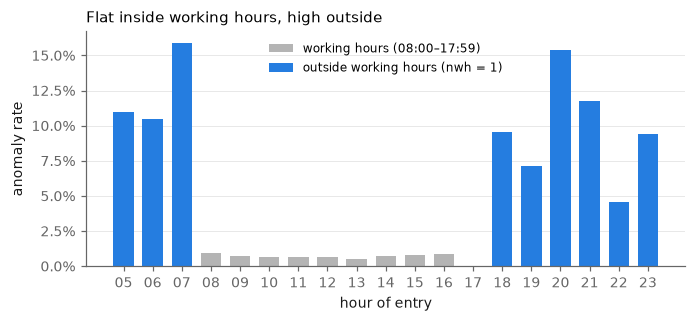

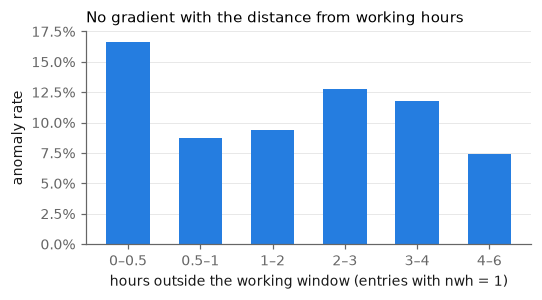

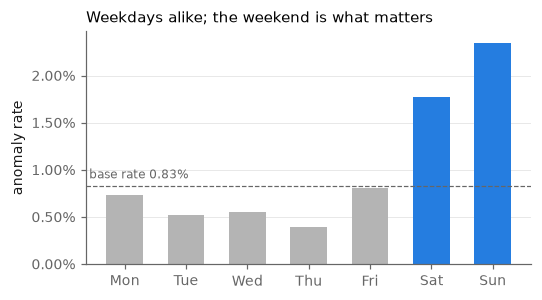

In [17]:
# cell_02_18
fig, t_hour = fg.fig_rate_by_hour(df1)
fg.save(fig, "fe_d11_rate_by_hour", FIG)
fig, t_dist = fg.fig_rate_by_distance(df1)
fg.save(fig, "fe_d11_rate_by_distance", FIG)
fig, t_wday = fg.fig_rate_by_weekday(df1)
fg.save(fig, "fe_d11_rate_by_weekday", FIG)
pd.concat({"by distance outside working hours": t_dist}).round(4)

### 6.5 D15 — identical vectors in the main setting (FY1, no labels)

largest group: 36 | groups of size > 1: 9280


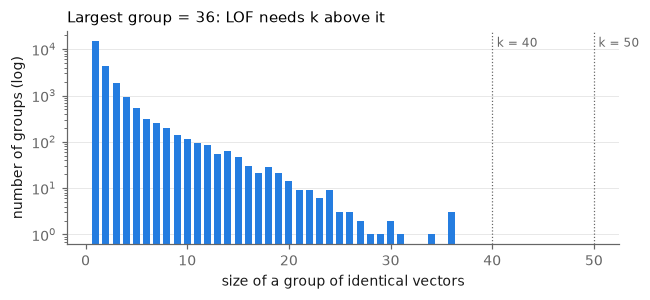

In [18]:
# cell_02_19
X_main_fy1, _ = fe.select_columns(X, feature_info, fe.FEATURE_GROUPS_MAIN)
fig, t_dup = fg.fig_duplicate_groups(X_main_fy1[is1].toarray())
fg.save(fig, "fe_d15_duplicate_groups", FIG)
print("largest group:", int(t_dup.index.max()), "| groups of size > 1:", int(t_dup[t_dup.index > 1].sum()))

## 7. Save

In [19]:
# cell_02_12
fe.save_encoding(X, feature_info, params,
                 DERIVED / "X_onehot.npz", DERIVED / "onehot_features.json")
print("saved:", DERIVED / "X_onehot.npz", DERIVED / "onehot_features.json")

saved: C:\MyWorks\Thesis\Jet\data\derived\X_onehot.npz C:\MyWorks\Thesis\Jet\data\derived\onehot_features.json


## 8. How later notebooks use it

Load once, then choose the feature groups per run. Write `fe.groups_label(groups)` into the `feature_groups` column of `results/runs.csv`.

In [20]:
# cell_02_13
X, feature_info, params = fe.load_encoding(DERIVED / "X_onehot.npz", DERIVED / "onehot_features.json")

main = fe.FEATURE_GROUPS_MAIN
X_main, names_main = fe.select_columns(X, feature_info, main)
print(fe.groups_label(main), X_main.shape)

all_on = {g: True for g in fe.ALL_GROUPS}
X_all, _ = fe.select_columns(X, feature_info, all_on)
print(fe.groups_label(all_on), X_all.shape)

no_time = fe.FEATURE_GROUPS_NO_TIME          # ablation without time features (D4)
print(fe.groups_label(no_time), fe.select_columns(X, feature_info, no_time)[0].shape)
assert X_main.shape[1] == 131                  # main setting after the 26 Nov redundancy check (v3)

lines+calendar_flags+lag_days@v3 (102429, 131)
lines+calendar_flags+lag_days+promptly+tax_rate+n_lines+nwh_dist+hour_cyc+wday_cyc@v3 (102429, 140)
lines@v3 (102429, 126)


## Notes for the thesis (Ch. 3, feature engineering)

- Fill in the numbers from sections 2, 4 and 5 (entries with changed line order, the single 4-line entry, mismatch counts).
- `user` and `tax_rate` are constant inside every entry. `user` is encoded once per entry (unlike Gronewald et al. 2024, who repeat it per slot); `tax_rate` and `n_lines` are not features (determined by the account pattern, D13; redundancy check in section 6.1).
- `promptly` is not a feature: it is a binning of `lag_days` (D4).
- D9: the CSV order is consistent within each of the 29 booking patterns; sorting makes the vector independent of how lines are stored (real extracts give no such guarantee).
- One entry has 4 lines; it alone uses slot 4. Check later where it ranks in the one-hot runs: if it appears at the top, it is a false positive caused by the encoding (the entry is normal), worth one sentence.
- Account / user / tax categories are taken from the whole ledger (no labels involved); numeric scalers are fitted per fiscal year (D10).